# autogradlite demo

A tensor-based autograd engine and tiny neural-net library, in the spirit of micrograd.

| Section | What it covers |
|---|---|
| 0. Setup | imports, helpers |
| 1. Scalar graph | the classic `L = (a*b + c) * f` example, with expected gradients |
| 2. Engine tests | every op gradient-checked against finite differences; broadcasting; NumPy interop |
| 3. The MLP | structure, parameter shapes, forward pass, graph |
| 4. MLP gradient check | backprop vs numerical gradients on every parameter |
| 5. Training | single sample, then a small batch |
| 6. Final sanity checks | dtypes and gradient shapes |

## 0. Setup

In [46]:
import os

# Optional: use a portable Graphviz in ./graphviz/bin (e.g. on Windows), only if that folder exists
dot_path = os.path.join(os.getcwd(), 'graphviz', 'bin')
if os.path.isdir(dot_path) and dot_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + dot_path

In [47]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

from autogradlite.engine import Tensor
from autogradlite.nn import MLP
from autogradlite.viz import draw_dot

rng = np.random.default_rng(0)


def T(*shape):
    """Random leaf Tensor of the given shape."""
    return Tensor(rng.standard_normal(shape))


def check(name, condition):
    """Tiny test helper: assert and print a tick."""
    assert condition, f"FAILED: {name}"
    print(f"✓ {name}")


def show_graph(root, **kwargs):
    """Render the computation graph, or say so if Graphviz isn't installed."""
    try:
        display(SVG(draw_dot(root, **kwargs).pipe(format='svg').decode('utf-8')))
    except Exception as e:
        print(f"(graph not rendered: {type(e).__name__}. Install Graphviz to see it.)")


def grad_check(f, inputs, eps=1e-2):
    """Max |autograd grad - finite-difference grad| over all elements of `inputs`.
    `f(*inputs)` must return a single-element Tensor."""
    for t in inputs:
        t.grad = np.zeros_like(t.data)
    f(*inputs).backward()
    worst = 0.0
    for t in inputs:
        flat, g = t.data.reshape(-1), t.grad.reshape(-1)   # flat is a view into t.data
        for i in range(flat.size):
            old = flat[i]
            flat[i] = old + eps; hi = f(*inputs).data.item()
            flat[i] = old - eps; lo = f(*inputs).data.item()
            flat[i] = old
            worst = max(worst, abs((hi - lo) / (2 * eps) - g[i]))
    return worst


print("All modules imported successfully!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
All modules imported successfully!


## 1. Scalar graph

`L = (a*b + c) * f` with `a=2, b=-3, c=10, f=-2`. By hand:
`e = a*b = -6`, `d = e + c = 4`, `L = d*f = -8`.
`dL/da = f*b = 6`, `dL/db = f*a = -4`, `dL/dc = f = -2`, `dL/df = d = 4`.

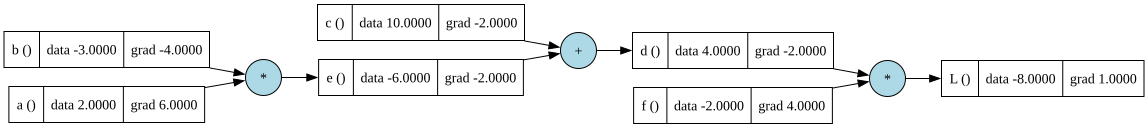

✓ L = -8
✓ dL/da = 6
✓ dL/db = -4
✓ dL/dc = -2
✓ dL/df = 4


In [48]:
a, b, c, f = Tensor(2.0), Tensor(-3.0), Tensor(10.0), Tensor(-2.0)
a.label, b.label, c.label, f.label = 'a', 'b', 'c', 'f'

e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
L = d * f;  L.label = 'L'
L.backward()

show_graph(L)

check("L = -8",        L.data.item() == -8)
check("dL/da = 6",     a.grad.item() == 6)
check("dL/db = -4",    b.grad.item() == -4)
check("dL/dc = -2",    c.grad.item() == -2)
check("dL/df = 4",     f.grad.item() == 4)

## 2. Engine tests

### 2a. Gradient check for every op
Each case builds a scalar from the op and compares autograd's gradient with a central finite difference.
The Tensors are float32, so errors of around 1e-4 are expected.

In [49]:
cases = [
    ("add, broadcast (2,3)+(3,)",        lambda x, b: ((x + b) ** 2).sum(),                      [T(2, 3), T(3)]),
    ("mul, broadcast (2,3)*(2,1)",       lambda x, c: ((x * c) ** 2).sum(),                      [T(2, 3), T(2, 1)]),
    ("python scalar constants",          lambda x: ((x * 2 - 1) ** 2).sum(),                     [T(2, 3)]),
    ("neg, sub, rsub",                   lambda x, y: ((1 - x - (-y)) ** 2).sum(),               [T(2, 3), T(2, 3)]),
    ("div, rdiv",                        lambda x, y: (x / (y * y + 1) + 1 / (y * y + 1)).sum(), [T(2, 3), T(2, 3)]),
    ("pow",                              lambda x: ((x * x + 1) ** 1.5).sum(),                   [T(2, 3)]),
    ("matmul (2,3)@(3,4)",               lambda x, W: ((x @ W) ** 2).sum(),                      [T(2, 3), T(3, 4)]),
    ("sum(axis=0)",                      lambda x: (x.sum(axis=0) ** 2).sum(),                   [T(2, 3)]),
    ("sum(axis=1, keepdims=True)",       lambda x: (x.sum(axis=1, keepdims=True) ** 2).sum(),    [T(2, 3)]),
    ("mean",                             lambda x: (x ** 2).mean(),                              [T(2, 3)]),
    ("relu",                             lambda x: (x.relu() ** 2).sum(),                        [T(2, 3)]),
    ("tanh",                             lambda x: x.tanh().sum(),                               [T(2, 3)]),
    ("exp",                              lambda x: x.exp().sum(),                                [T(2, 3)]),
    ("log",                              lambda x: (x * x + 1).log().sum(),                      [T(2, 3)]),
    ("shared node (x used twice)",       lambda x: (x * x + x).sum(),                            [T(2, 3)]),
]

for name, fn, inputs in cases:
    err = grad_check(fn, inputs)
    check(f"{name:32s} max err {err:.1e}", err < 5e-3)

✓ add, broadcast (2,3)+(3,)        max err 4.4e-05
✓ mul, broadcast (2,3)*(2,1)       max err 1.6e-05
✓ python scalar constants          max err 5.9e-05
✓ neg, sub, rsub                   max err 6.2e-05
✓ div, rdiv                        max err 2.0e-04
✓ pow                              max err 1.5e-04
✓ matmul (2,3)@(3,4)               max err 6.2e-05
✓ sum(axis=0)                      max err 2.1e-05
✓ sum(axis=1, keepdims=True)       max err 3.9e-05
✓ mean                             max err 4.0e-06
✓ relu                             max err 1.4e-05
✓ tanh                             max err 2.9e-05
✓ exp                              max err 4.4e-05
✓ log                              max err 4.1e-05
✓ shared node (x used twice)       max err 1.5e-05


### 2b. Broadcasting
`b` has shape `(3,)` and is reused for both rows of `x`, so its gradient must be the sum over rows.

In [50]:
x = Tensor([[1, 2, 3], [4, 5, 6]])
b = Tensor([10, 20, 30])
(x + b).sum().backward()

print("b.grad:", b.grad)
check("b.grad = column sums of ones = [2, 2, 2]", np.allclose(b.grad, [2, 2, 2]))
check("x.grad has x's shape",                     x.grad.shape == x.data.shape)
check("b.grad has b's shape",                     b.grad.shape == b.data.shape)

b.grad: [2. 2. 2.]
✓ b.grad = column sums of ones = [2, 2, 2]
✓ x.grad has x's shape
✓ b.grad has b's shape


### 2c. NumPy interop and type checks
`__array_ufunc__ = None` makes `ndarray <op> Tensor` fall back to the Tensor's reflected methods.

In [51]:
arr = np.ones((2, 3), dtype=np.float32)
t = Tensor(np.full((2, 3), 2.0))

results = {
    "ndarray + Tensor": arr + t,
    "ndarray - Tensor": arr - t,
    "ndarray * Tensor": arr * t,
    "ndarray / Tensor": arr / t,
    "ndarray @ Tensor": arr @ Tensor(np.ones((3, 2))),
    "int - Tensor":     1 - t,
    "Tensor - float":   t - 0.5,
}
for name, r in results.items():
    check(f"{name} -> Tensor", isinstance(r, Tensor))

check("Tensor data is float32", t.data.dtype == np.float32)
check("Tensor.shape property",  t.shape == (2, 3))

try:
    Tensor([1.0, 2.0, 3.0]) @ Tensor(np.ones((3, 2)))
    rejected = False
except AssertionError:
    rejected = True
check("1-D matmul is rejected (needs 2-D)", rejected)

✓ ndarray + Tensor -> Tensor
✓ ndarray - Tensor -> Tensor
✓ ndarray * Tensor -> Tensor
✓ ndarray / Tensor -> Tensor
✓ ndarray @ Tensor -> Tensor
✓ int - Tensor -> Tensor
✓ Tensor - float -> Tensor
✓ Tensor data is float32
✓ Tensor.shape property
✓ 1-D matmul is rejected (needs 2-D)


### 2d. Gotcha: mismatched target shapes broadcast silently
If predictions are `(batch, 1)` but targets are `(batch,)`, `pred - y` becomes a `(batch, batch)` matrix and the loss is wrong. Autograd won't warn you, so always shape targets to match predictions.

In [52]:
pred = Tensor(np.zeros((4, 1)))
print("(4,1) - (4,)   ->", (pred - np.zeros(4)).shape,    " <- silently wrong")
print("(4,1) - (4,1)  ->", (pred - np.zeros((4, 1))).shape, " <- what you want")

(4,1) - (4,)   -> (4, 4)  <- silently wrong
(4,1) - (4,1)  -> (4, 1)  <- what you want


## 3. The MLP

`MLP(3, [4, 4, 1])`: 3 input features, two hidden ReLU layers of 4 neurons, one linear output.
Each `Layer` holds `W` of shape `(nin, nout)` (column *j* = neuron *j*'s weights) and `b` of shape `(nout,)`.
Parameter count per layer is `(nin + 1) * nout`: 16 + 20 + 5 = 41.

In [53]:
np.random.seed(0)
model = MLP(3, [4, 4, 1])

for i, layer in enumerate(model.layers):
    print(f"layer {i}: W {layer.W.shape}, b {layer.b.shape}, ReLU: {layer.nonlin}")

n_params = sum(p.data.size for p in model.parameters())
print("total parameters:", n_params)

check("41 parameters",              n_params == 41)
check("last layer is linear",       model.layers[-1].nonlin is False)
check("hidden layers use ReLU",     all(l.nonlin for l in model.layers[:-1]))

layer 0: W (3, 4), b (4,), ReLU: True
layer 1: W (4, 4), b (4,), ReLU: True
layer 2: W (4, 1), b (1,), ReLU: False
total parameters: 41
✓ 41 parameters
✓ last layer is linear
✓ hidden layers use ReLU


In [54]:
# One sample is a (1, 3) row; a batch is (batch, 3).
x_one   = np.array([[2.0, 3.0, -1.0]])
x_batch = rng.standard_normal((5, 3))

out_one, out_batch = model(x_one), model(x_batch)
print("one sample ->", out_one.shape, "| batch of 5 ->", out_batch.shape)

check("output is a Tensor",             isinstance(out_one, Tensor))
check("one sample -> (1, 1)",           out_one.shape == (1, 1))
check("batch of 5 -> (5, 1)",           out_batch.shape == (5, 1))
check("batching doesn't change rows",   np.allclose(model(x_batch[:1]).data, out_batch.data[:1], atol=1e-6))

one sample -> (1, 1) | batch of 5 -> (5, 1)
✓ output is a Tensor
✓ one sample -> (1, 1)
✓ batch of 5 -> (5, 1)
✓ batching doesn't change rows


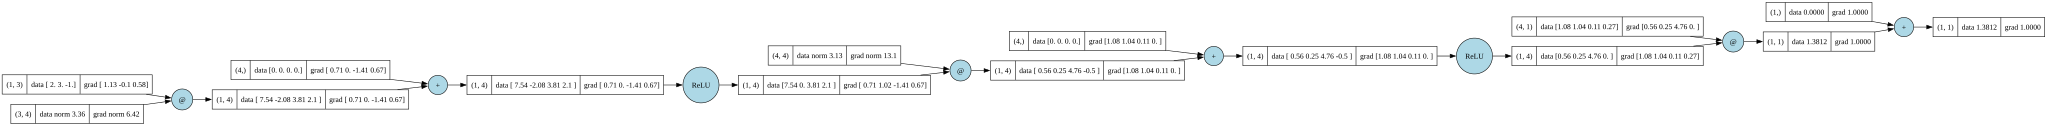

In [55]:
# Computation graph for one forward pass (scalars show values, tensors show shape and norms)
model.zero_grad()
out = model(x_one)
out.backward()
show_graph(out)

## 4. Gradient check on the whole MLP

Backprop vs finite differences, for every element of every `W` and `b`, on a batch of 4 samples.

In [56]:
X = np.array([[2.0,  3.0, -1.0],
              [3.0, -1.0,  0.5],
              [0.5,  1.0,  1.0],
              [1.0,  1.0, -1.0]])
y = np.array([[1.0], [-1.0], [-1.0], [1.0]])     # shape (4, 1), same as the predictions


def mse_loss(pred, y):
    return ((pred - y) ** 2).mean()


np.random.seed(1)
model = MLP(3, [4, 4, 1])
err = grad_check(lambda *_: mse_loss(model(X), y), model.parameters())
check(f"MLP backprop matches finite differences (max err {err:.1e})", err < 5e-3)

✓ MLP backprop matches finite differences (max err 4.1e-05)


## 5. Training

Each step is: forward → loss → `zero_grad` → `backward` → SGD update.
The update is done in place (`p.data -= ...`) so parameters stay float32.

In [57]:
def train(model, X, y, lr=0.05, epochs=200, log_every=None):
    history = []
    for epoch in range(epochs):
        loss = mse_loss(model(X), y)        # 1. forward + loss
        model.zero_grad()                   # 2. clear old gradients
        loss.backward()                     # 3. backward
        for p in model.parameters():        # 4. gradient descent step
            p.data -= lr * p.grad
        history.append(float(loss.data))
        if log_every and (epoch + 1) % log_every == 0:
            print(f"Epoch {epoch + 1:3d} | Loss: {history[-1]:.6f}")
    return history

### 5a. One sample

In [58]:
np.random.seed(42)
model = MLP(3, [4, 4, 1])

xs = np.array([[1.5, 0.5, -0.5]])
target = np.array([[1.0]])

history = train(model, xs, target, lr=0.05, epochs=40, log_every=5)
check("loss decreased",          history[-1] < history[0])
check("loss is now small (< 1e-3)", history[-1] < 1e-3)

Epoch   5 | Loss: 0.393044
Epoch  10 | Loss: 0.137046
Epoch  15 | Loss: 0.047785
Epoch  20 | Loss: 0.016662
Epoch  25 | Loss: 0.005810
Epoch  30 | Loss: 0.002026
Epoch  35 | Loss: 0.000706
Epoch  40 | Loss: 0.000246
✓ loss decreased
✓ loss is now small (< 1e-3)


### 5b. A small batch

Epoch  40 | Loss: 0.909996
Epoch  80 | Loss: 0.386602
Epoch 120 | Loss: 0.025900
Epoch 160 | Loss: 0.000224
Epoch 200 | Loss: 0.000009


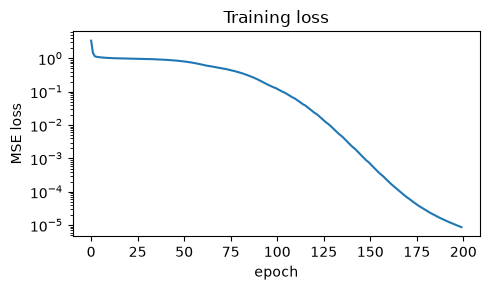

targets:     [ 1. -1. -1.  1.]
predictions: [ 1.    -1.    -1.     0.994]
✓ final loss < 1e-2
✓ predictions match targets


In [59]:
np.random.seed(1)
model = MLP(3, [4, 4, 1])

history = train(model, X, y, lr=0.05, epochs=200, log_every=40)

plt.figure(figsize=(5, 3))
plt.plot(history)
plt.yscale('log')
plt.xlabel('epoch'); plt.ylabel('MSE loss'); plt.title('Training loss')
plt.tight_layout(); plt.show()

preds = model(X).data
print("targets:    ", y.ravel())
print("predictions:", np.round(preds.ravel(), 3))

check("final loss < 1e-2",          history[-1] < 1e-2)
check("predictions match targets",  np.allclose(preds, y, atol=0.2))

## 6. Final sanity checks

In [60]:
check("all parameters are float32",          all(p.data.dtype == np.float32 for p in model.parameters()))
check("all gradients are float32",           all(p.grad.dtype == np.float32 for p in model.parameters()))
check("every grad has its parameter's shape", all(p.grad.shape == p.data.shape for p in model.parameters()))

model.zero_grad()
check("zero_grad clears all gradients",      all(not p.grad.any() for p in model.parameters()))
print("\nAll checks passed.")

✓ all parameters are float32
✓ all gradients are float32
✓ every grad has its parameter's shape
✓ zero_grad clears all gradients

All checks passed.
